# Lab 1: Базові алгоритми класифікації у Scikit-learn
## Завдання
1) Завантаження та первинний аналіз даних: завантажити датасет; вивести назви колонок та розмір датасета; визначити ознаки (features) та цільову змінну (target); перевірити типи даних та розподіл об'єктів за класами.

In [13]:
import pandas as pd

df = pd.read_csv('uci-secom.csv')

print(f"Розмір датасета: {df.shape[0]} записів {df.shape[1]} ознак.")

print("\nНазви колонок (частково):")
print(list(df.columns[:10]) + ['...'] + list(df.columns[-5:]))

target_col = 'Pass/Fail'
features = [col for col in df.columns if col not in ['Time', target_col]]

print(f"\nЦільова змінна: '{target_col}'")
print(f"Кількість ознак для навчання: {len(features)}")

print("\nТипи даних (загальне зведення):")
print(df.dtypes.value_counts())

print("\nРозподіл об'єктів за класами Pass/Fail:")
print(df[target_col].value_counts())

print("\nВідсоткове співвідношення класів (%):")
print((df[target_col].value_counts(normalize=True) * 100).round(2))

Розмір датасета: 1567 записів 592 ознак.

Назви колонок (частково):
['Time', '0', '1', '2', '3', '4', '5', '6', '7', '8', '...', '586', '587', '588', '589', 'Pass/Fail']

Цільова змінна: 'Pass/Fail'
Кількість ознак для навчання: 590

Типи даних (загальне зведення):
float64    590
str          1
int64        1
Name: count, dtype: int64

Розподіл об'єктів за класами Pass/Fail:
Pass/Fail
-1    1463
 1     104
Name: count, dtype: int64

Відсоткове співвідношення класів (%):
Pass/Fail
-1    93.36
 1     6.64
Name: proportion, dtype: float64


2) Попередня обробка даних: перевірити наявність пропущених значень; за необхідності заповнити або видалити пропуски; якщо датасет містить категоріальні ознаки, виконати їх кодування; коротко пояснити прийняті рішення щодо попередньої обробки даних.

In [14]:
print(f"Загальна кількість пропущених значень ДО обробки: {df.isna().sum().sum()}")

if 'Time' in df.columns:
    df = df.drop(columns=['Time'])

threshold = 0.5 * df.shape[0]
df = df.dropna(thresh=threshold, axis=1)
print(f"Залишилося колонок після видалення тих, де >50% пропусків: {df.shape[1]}")

constant_columns = [col for col in df.columns if df[col].nunique() <= 1 and col != target_col]
df = df.drop(columns=constant_columns)
print(f"Залишилося колонок після видалення константних (марних) ознак: {df.shape[1]}")

# Заповнення залишків пропусків медіаною
features = [col for col in df.columns if col != target_col]
# Використовуємо fillna з медіаною для кожної ознаки
df[features] = df[features].fillna(df[features].median())

print(f"Загальна кількість пропущених значень ПІСЛЯ обробки: {df.isna().sum().sum()}")

# Кодування цільової змінної
df[target_col] = df[target_col].replace({-1: 0, 1: 1})

print(f"\nУнікальні значення цільової змінної після заміни: {df[target_col].unique()}")

Загальна кількість пропущених значень ДО обробки: 41951
Залишилося колонок після видалення тих, де >50% пропусків: 563
Залишилося колонок після видалення константних (марних) ознак: 447
Загальна кількість пропущених значень ПІСЛЯ обробки: 0

Унікальні значення цільової змінної після заміни: [0 1]


3) Візуалізація та дослідження даних - провести базовий Exploratory Data Analysis (EDA): побудувати heatmap кореляцій числових ознак; побудувати гістограми розподілу ознак; побудувати boxplot-и ознак відносно цільової змінної; коротко прокоментувати отримані візуалізації.
Якщо ознак багато, для візуалізації можна обмежитися декількома найбільш інформативними.

Топ-11 найбільш інформативних сенсорів ДО чистки: 
['Pass/Fail', '59', '103', '510', '348', '431', '434', '430', '21', '435', '28', '436', '210']



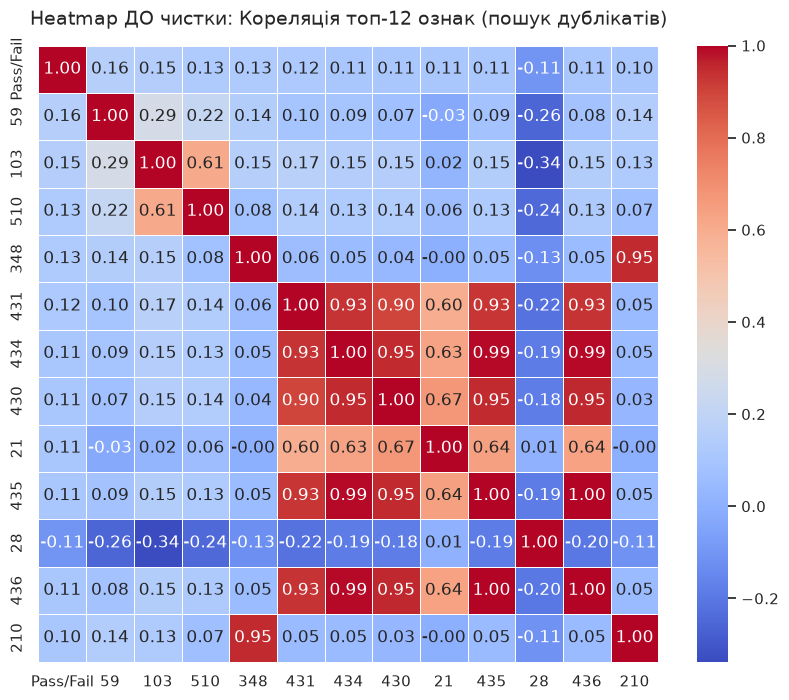

Видалено 185 дублюючих ознак (залишено ті, що краще корелюють з таргетом).
Залишилося унікальних колонок у датасеті: 262

Нові Топ-12 чистих сенсорів для подальшого аналізу: 
['Pass/Fail', '59', '103', '510', '348', '431', '434', '21', '28', '129', '298', '124', '295']



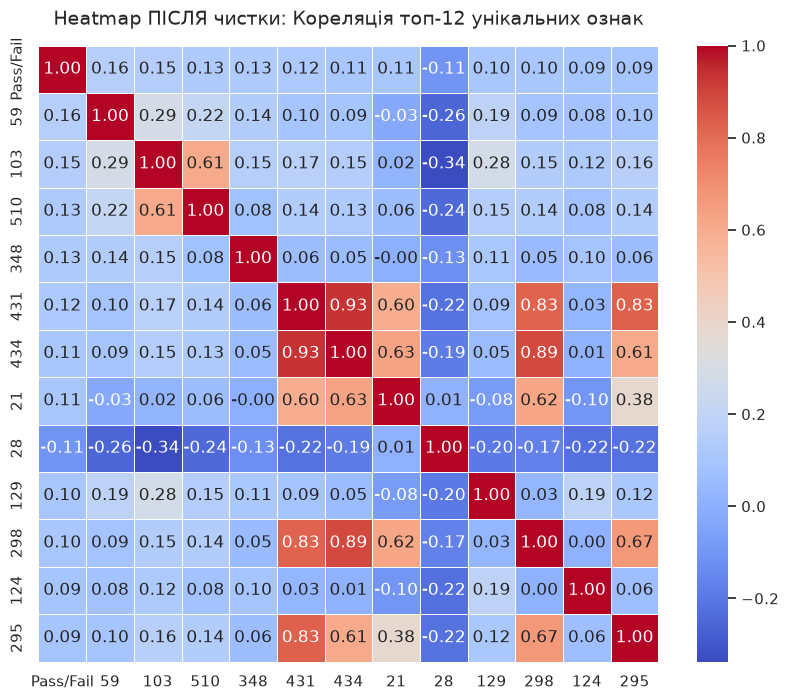

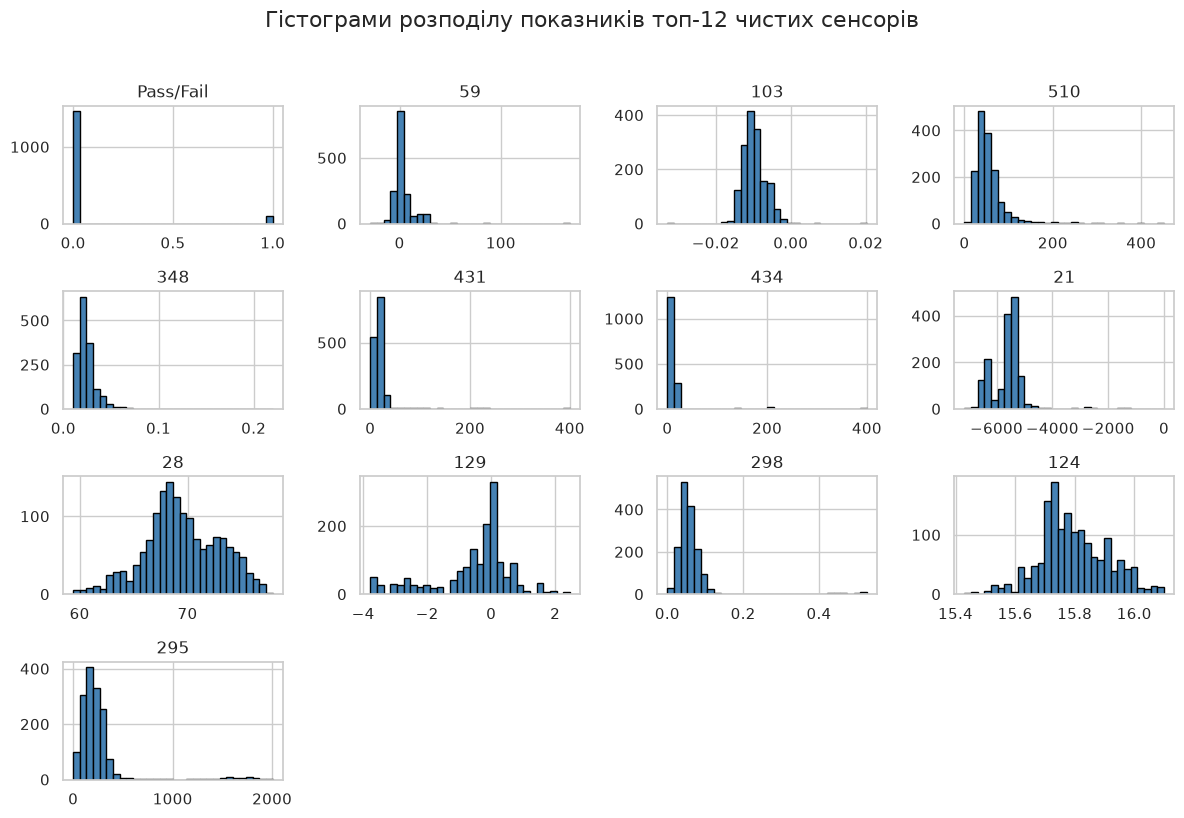

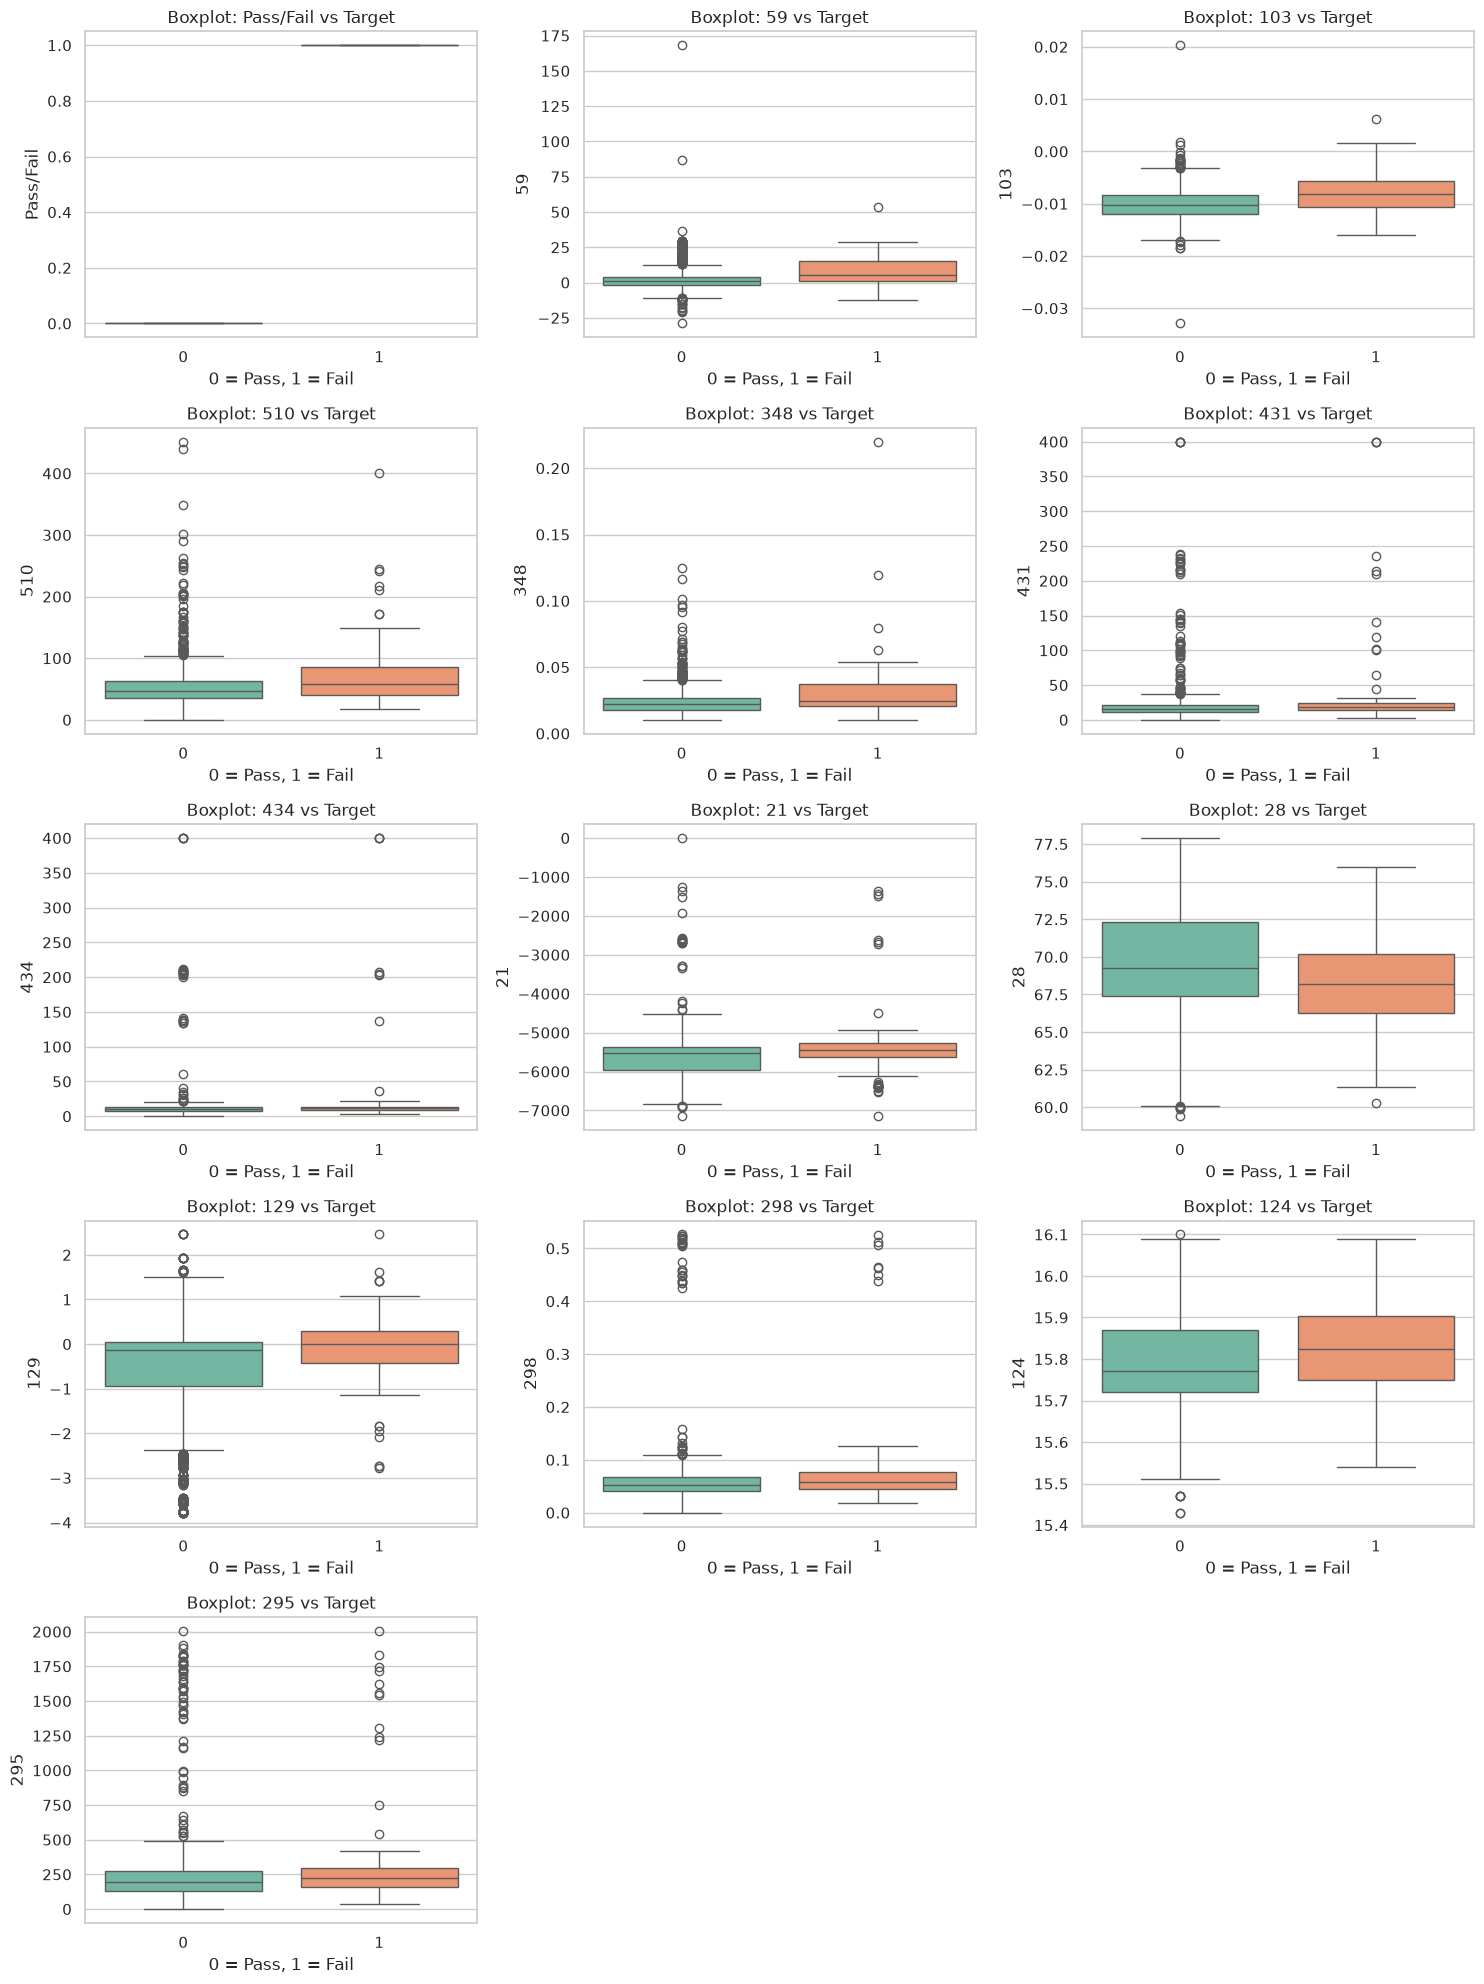

Будуємо теплову карту для решти 261 ознак...


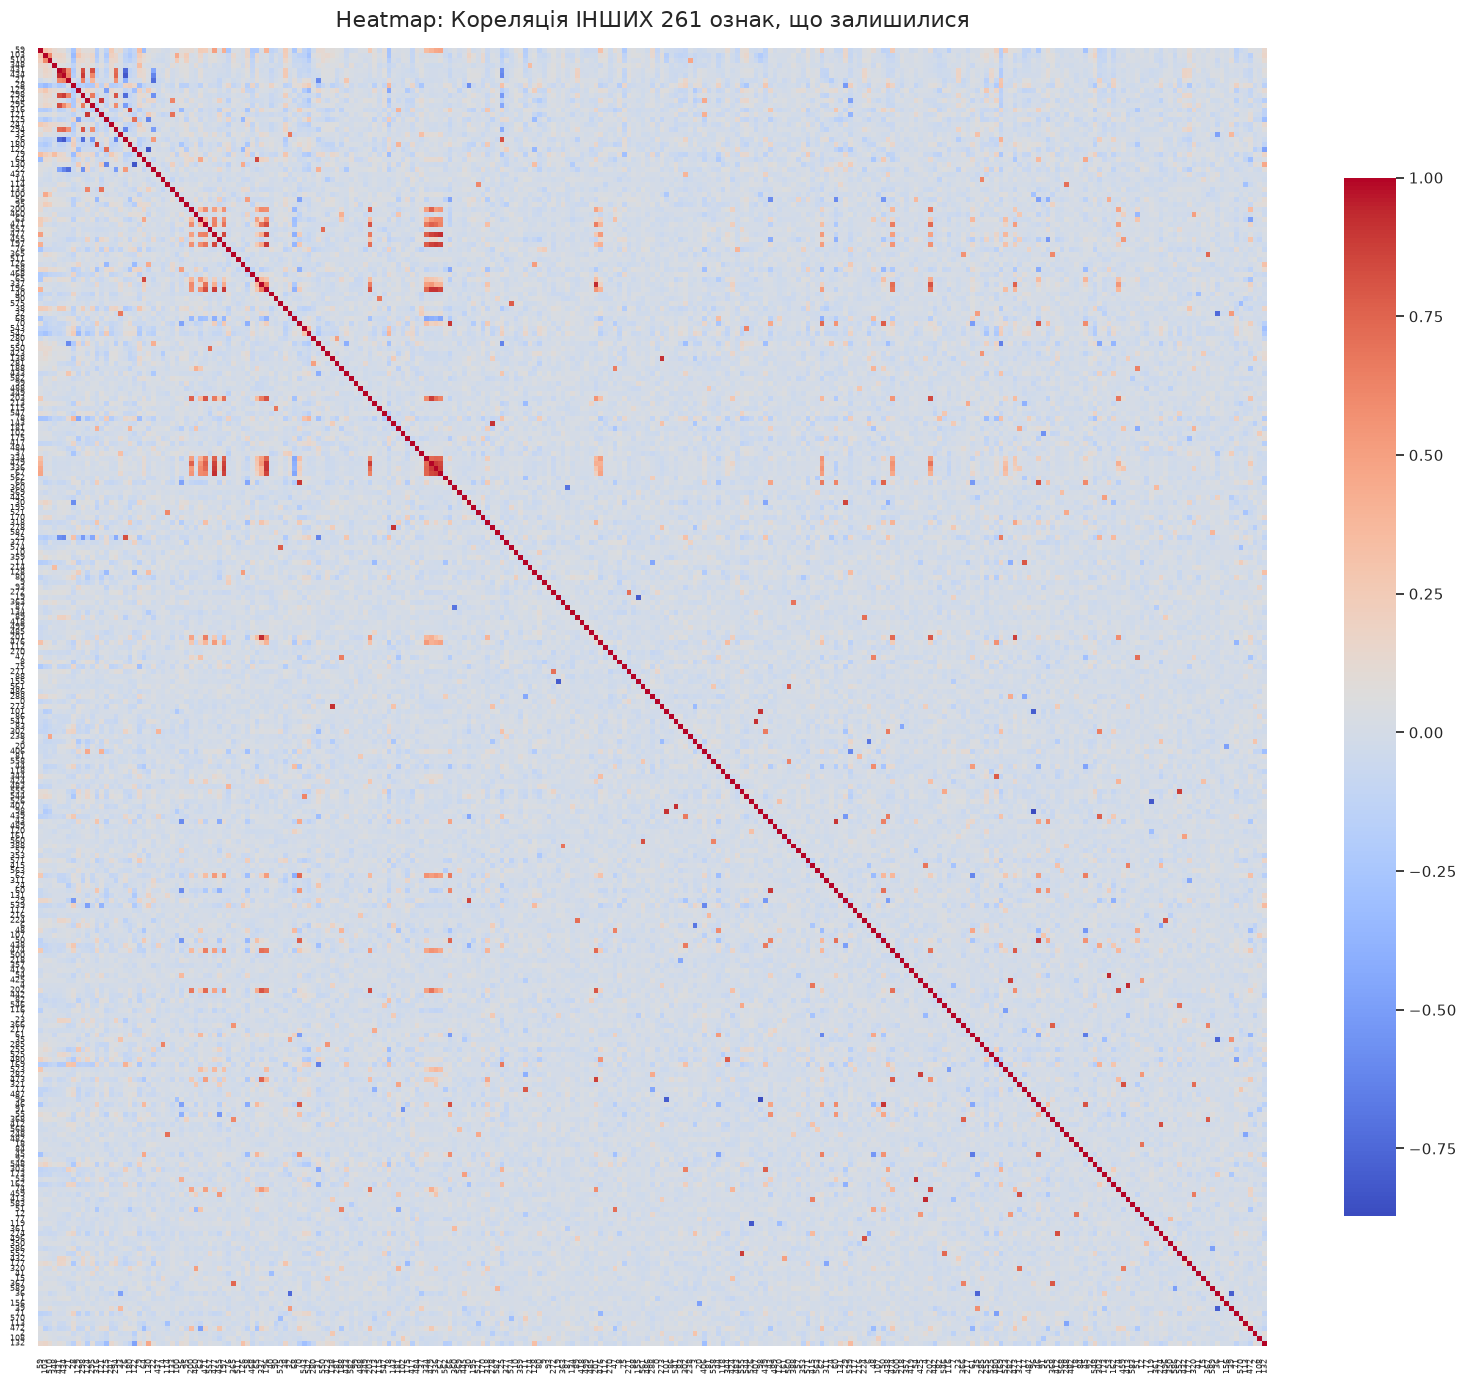

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

sns.set_theme(style="whitegrid")

# ==========================================
# ЕТАП 1: ДО ЧИСТКИ (Аналіз проблеми)
# ==========================================
# Шукаємо 11 найбільш корельованих з таргетом ознак для першого графіку
correlations_before = df.corr()[target_col].abs().sort_values(ascending=False)
top_features_before = correlations_before.index[:13].tolist()

print(f"Топ-11 найбільш інформативних сенсорів ДО чистки: \n{top_features_before}\n")

plt.figure(figsize=(10, 8))
sns.heatmap(df[top_features_before].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Heatmap ДО чистки: Кореляція топ-12 ознак (пошук дублікатів)', fontsize=14, pad=15)
plt.show()

# ==========================================
# ЕТАП 2: ВИДАЛЕННЯ МУЛЬТИКОЛІНЕАРНОСТІ
# ==========================================
# 1. Знаходимо кореляцію всіх ознак з таргетом і сортуємо їх за спаданням важливості
target_correlations = df.corr()[target_col].abs().sort_values(ascending=False)
features_sorted = target_correlations.drop(target_col).index.tolist()

# 2. Перебудовуємо датасет так, щоб найважливіші сенсори йшли першими
df = df[features_sorted + [target_col]]

# 3. Рахуємо матрицю кореляцій між самими сенсорами (вони вже відсортовані за важливістю)
corr_matrix = df.drop(columns=[target_col]).corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# 4. Тепер, якщо скрипт знаходить дублікат > 0.95, у список на видалення потрапляє колонка, 
# яка стоїть ПРАВІШЕ (тобто та, яка має меншу кореляцію з таргетом). Сильні ознаки у безпеці!
to_drop = [column for column in upper.columns if any(upper[column] > 0.94)]

df = df.drop(columns=to_drop)

print(f"Видалено {len(to_drop)} дублюючих ознак (залишено ті, що краще корелюють з таргетом).")
print(f"Залишилося унікальних колонок у датасеті: {df.shape[1]}\n")

# ==========================================
# ЕТАП 3: ПІСЛЯ ЧИСТКИ (Фінальні візуалізації)
# ==========================================
# Перераховуємо кореляцію на вже ОЧИЩЕНОМУ датасеті і беремо топ-6
correlations_after = df.corr()[target_col].abs().sort_values(ascending=False)
top_features_after = correlations_after.index[:13].tolist()

print(f"Нові Топ-12 чистих сенсорів для подальшого аналізу: \n{top_features_after}\n")

# 1. Heatmap чистих ознак
plt.figure(figsize=(10, 8))
sns.heatmap(df[top_features_after].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Heatmap ПІСЛЯ чистки: Кореляція топ-12 унікальних ознак', fontsize=14, pad=15)
plt.show()

# 2. Гістограми розподілу чистих ознак
df[top_features_after].hist(bins=30, figsize=(12, 8), color='steelblue', edgecolor='black')
plt.suptitle('Гістограми розподілу показників топ-12 чистих сенсорів', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# 3. Boxplot-и чистих ознак відносно цільової змінної
# 3. Boxplot-и чистих ознак відносно цільової змінної (Динамічна сітка)
n_features = len(top_features_after)
cols = 3 # Завжди малюємо по 3 графіки в ряд
rows = math.ceil(n_features / cols) # Автоматично рахуємо кількість рядків

# Висота графіка теж підлаштовується автоматично (по 4 дюйми на кожен ряд)
plt.figure(figsize=(15, rows * 4))

for i, col in enumerate(top_features_after, 1):
    plt.subplot(rows, cols, i)
    sns.boxplot(x=target_col, y=col, data=df, hue=target_col, palette='Set2', legend=False)
    plt.title(f'Boxplot: {col} vs Target')
    plt.xlabel('0 = Pass, 1 = Fail')

plt.tight_layout()
plt.show()

# ==========================================
# ЕТАП 4: ДОДАТКОВИЙ АНАЛІЗ (Усі інші ознаки)
# ==========================================
# Відбираємо всі ознаки, які залишилися, крім цільової та тих, що вже були на попередньому графіку
remaining_features = [col for col in df.columns if col != target_col]

print(f"Будуємо теплову карту для решти {len(remaining_features)} ознак...")

plt.figure(figsize=(16, 14))
sns.heatmap(df[remaining_features].corr(), 
            annot=False,          # Вимикаємо цифри, залишаємо тільки кольори
            cmap='coolwarm', 
            xticklabels=True, 
            yticklabels=True,
            cbar_kws={"shrink": .8})

plt.title(f'Heatmap: Кореляція ІНШИХ {len(remaining_features)} ознак, що залишилися', fontsize=16, pad=15)

# Робимо підписи дрібнішими, щоб вони помістилися на осях
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.show()

4) Підготовка даних до навчання: розділити дані на training та test вибірки; виконати масштабування/нормалізацію ознак для алгоритмів, для яких це необхідно.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Розділяємо датасет на матрицю ознак (X) та вектор цільової змінної (y)
# Відкидаємо target_col, щоб він не потрапив у тренувальні дані
X = df.drop(columns=[target_col])
y = df[target_col]

# 2. Розбиваємо на train та test (80% / 20%) зі збереженням балансу класів (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Ініціалізуємо скалер
scaler = StandardScaler()

# УВАГА: Навчаємо скалер (fit) ТІЛЬКИ на тренувальній вибірці і одразу трансформуємо її
X_train_scaled = scaler.fit_transform(X_train)

# Тестову вибірку ЛИШЕ трансформуємо (за правилами, виведеними з train)
X_test_scaled = scaler.transform(X_test)

# 3. Стиснення розмірності через PCA
# Просимо алгоритм стиснути всі наявні колонки у 20 найголовніших векторів
pca = PCA(n_components=100, random_state=42)

# Навчаємо стиснення ТІЛЬКИ на тренувальних даних, а потім просто трансформуємо обидві вибірки
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Розмір початкових даних (X): {X.shape}")
print(f"Розмір тренувальної вибірки (X_train_scaled): {X_train_scaled.shape}")
print(f"Кількість браку в train: {sum(y_train == 1)} ({sum(y_train == 1)/len(y_train)*100:.1f}%)")
print(f"Розмір тестової вибірки (X_test_scaled): {X_test_scaled.shape}")
print(f"Кількість браку в test: {sum(y_test == 1)} ({sum(y_test == 1)/len(y_test)*100:.1f}%)")

Розмір початкових даних (X): (1567, 261)
Розмір тренувальної вибірки (X_train_scaled): (1253, 261)
Кількість браку в train: 83 (6.6%)
Розмір тестової вибірки (X_test_scaled): (314, 261)
Кількість браку в test: 21 (6.7%)


In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.model_selection import GridSearchCV

# 1. k-Nearest Neighbors (kNN) + GridSearchCV
knn_params = {'n_neighbors': [3, 5, 7, 9, 11]}
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=3, scoring='f1_macro', n_jobs=-1)
knn_grid.fit(X_train_scaled, y_train)
best_knn = knn_grid.best_estimator_
print(f"kNN найкращий параметр: {knn_grid.best_params_}")

# 2. Support Vector Machine (SVM) + GridSearchCV
svm_params = {'C': [0.1, 1, 10], 'gamma': ['scale', 0.1, 0.01]}
svm_grid = GridSearchCV(SVC(class_weight='balanced', random_state=42), svm_params, cv=3, scoring='f1_macro', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)
best_svm = svm_grid.best_estimator_
print(f"SVM найкращі параметри: {svm_grid.best_params_}")

# 3. Decision Tree
dt = DecisionTreeClassifier(class_weight='balanced', random_state=42)
dt.fit(X_train_scaled, y_train)
print("Decision Tree навчено")

# 4. Random Forest
rf = RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100)
rf.fit(X_train_scaled, y_train)
print("Random Forest навчено")

# 5. AdaBoost
ada = AdaBoostClassifier(random_state=42)
ada.fit(X_train_scaled, y_train)
print("AdaBoost навчено\n")

# Зберігаємо всі моделі у словник для зручної оцінки
models = {
    'k-Nearest Neighbors': best_knn,
    'Decision Tree': dt,
    'Support Vector Machine': best_svm,
    'Random Forest': rf,
    'AdaBoost': ada
}

kNN найкращий параметр: {'n_neighbors': 5}
SVM найкращі параметри: {'C': 0.1, 'gamma': 'scale'}
Decision Tree навчено
Random Forest навчено
AdaBoost навчено



In [18]:
from sklearn.metrics import classification_report, confusion_matrix

for name, model in models.items():
    # Робимо передбачення на тестовій вибірці
    y_pred = model.predict(X_test_scaled)
    
    print("="*50)
    print(f"МОДЕЛЬ: {name}")
    print("="*50)
    
    # Виводимо Classification Report
    print("Classification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    # Виводимо текстову Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:")
    print(f"True Negatives (TN): {cm[0][0]} | False Positives (FP): {cm[0][1]}")
    print(f"False Negatives (FN): {cm[1][0]}  | True Positives (TP): {cm[1][1]}\n")

МОДЕЛЬ: k-Nearest Neighbors
Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.97       293
           1       0.50      0.10      0.16        21

    accuracy                           0.93       314
   macro avg       0.72      0.54      0.56       314
weighted avg       0.91      0.93      0.91       314

Confusion Matrix:
True Negatives (TN): 291 | False Positives (FP): 2
False Negatives (FN): 19  | True Positives (TP): 2

МОДЕЛЬ: Decision Tree
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       293
           1       0.09      0.05      0.06        21

    accuracy                           0.90       314
   macro avg       0.51      0.51      0.51       314
weighted avg       0.88      0.90      0.89       314

Confusion Matrix:
True Negatives (TN): 283 | False Positives (FP): 10
False Negatives (FN): 20  | True Positives (TP): 1

МОДЕЛЬ: